# Tópico 2: Recortes Temporais do Lucro (Ano, Década, Gêneros e Ajuste de Inflação)

**Projeto da Matéria de Ciência de Dados — TMDB**  
**Checklist (Checkpoint 2) — Tópico 2 Expandido:**
- Agrupar os dados financeiros por ano de lançamento e por décadas.
- Mapear a evolução do lucro médio e total ao longo dos anos.
- **Ajuste pela Inflação Histórica (CPI-U base 2024):** Mapear faturamento, orçamento e lucro em valores reais (poder de compra constante).
- **Frequência de Gêneros por Década:** Volume de produções lançadas em cada gênero.
- **Lucro dos Gêneros por Década:** Quais gêneros dominaram cada época e como esse comportamento se transformou ao longo da história.


## Importação e Início

In [1]:
# utilizar os Dataframes do Pandas para manipular as instâncias
import pandas as pd
import numpy as np

# matplotlib e seaborn para visualizar
import matplotlib.pyplot as plt
import seaborn as sns

# gdown para baixar os dados
import gdown
import os
from datetime import datetime
import warnings

# suprime warnings de visualização e depreciação
warnings.filterwarnings('ignore')

# estilo padrão do projeto
plt.style.use('ggplot')


In [2]:
url = 'https://drive.google.com/file/d/10izoanxrZJnQzkV9UpPI-DX9bt2mYG62/view'
output = 'filmes.json'

if not os.path.exists("filmes.json"):
    gdown.download(url=url, output="filmes.json", quiet=False)

df = pd.read_json('filmes.json', orient='records')
print(f"Número inicial de registros: {len(df)}")
df.head(3)


Número inicial de registros: 16541


,adult,backdrop_path,belongs_to_collection,budget,genres,homepage,id,imdb_id,origin_country,original_language,...,softcore,spoken_languages,status,tagline,title,video,vote_average,vote_count,profit,roi
0,False,/7RyHsO4yDXtBv1zUU3mTpHeQ0d5.jpg,"{'id': 86311, 'name': 'The Avengers Collection...",356000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 878, ...",https://www.marvel.com/movies/avengers-endgame,299534,tt4154796,[US],en,...,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Avenge the fallen.,Avengers: Endgame,False,8.247,29099,2582567784,7.2544
1,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,"{'id': 87096, 'name': 'Avatar Collection', 'po...",237000000,"[{'id': 878, 'name': 'Science Fiction'}, {'id'...",https://www.avatar.com/movies/avatar,19995,tt0499549,[US],en,...,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Enter the world of Pandora.,Avatar,False,7.611,34904,2686706026,11.3363
2,False,/r08LxMJCbf1SiJIWeyH9aJmdqwC.jpg,"{'id': 531241, 'name': 'Spider-Man (MCU) Colle...",225000000,"[{'id': 878, 'name': 'Science Fiction'}, {'id'...",https://spidermanbrandnewday.movie,969681,tt22084616,[US],en,...,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,A brand new day starts now.,Spider-Man: Brand New Day,False,8.468,6037,2291291000,10.1835


## Limpeza, Sanidade e Ajuste pela Inflação Histórica

Para que as análises econômicas sejam cientificamente válidas:
1. **Filtro temporal:** status 'Released', datas válidas entre 1888 e hoje.
2. **Remoção de duplicatas:** por `id` e pela combinação `[title, release_date]`.
3. **Filtro de sanidade financeira:** `budget > 0`, `revenue > 0` e `vote_count > 0`.
4. **Ajuste pela Inflação (US CPI-U, Base 2024 USD):**  
   Comparar nominalmente US\$ 400M em 1939 (*...E o Vento Levou*) com US\$ 2,7B em 2019 (*Vingadores: Ultimato*) distorce a história, pois US\$ 1 de 1939 comprava o equivalente a mais de US\$ 22 hoje.  
   Utilizamos a série histórica oficial do **Índice de Preços ao Consumidor dos EUA (CPI-U)** do *U.S. Bureau of Labor Statistics* (1913–2026), indexando todos os valores monetários a dólares reais de 2024.


In [3]:
tamanho_inicial = len(df)

# 1. Filtro Temporal
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
hoje = pd.Timestamp(datetime.now().date())

condicao_valida = (
    (df['status'] == 'Released') & 
    (df['release_date'].notnull()) & 
    (df['release_date'] <= hoje) & 
    (df['release_date'].dt.year >= 1888)
)
df = df[condicao_valida].copy()

# 2. Remoção de Duplicatas
df = df.drop_duplicates(subset=['id'], keep='first')
df = df.drop_duplicates(subset=['title', 'release_date'], keep='first')

# 3. Sanidade Financeira (Budget, Revenue e Vote Count > 0)
condicao_sanidade = (
    (df['budget'] > 0) & 
    (df['revenue'] > 0) & 
    (df['vote_count'] > 0)
)
df = df[condicao_sanidade].copy()

# 4. Feature Engineering Temporal e Financeira
df['year'] = df['release_date'].dt.year.astype(int)
df['decada'] = (df['year'] // 10) * 10
df['profit'] = df['revenue'] - df['budget']
df['roi'] = (df['revenue'] - df['budget']) / df['budget']

# 5. Série Histórica do US CPI-U (Média Anual, 1913 a 2026)
cpi_historico = {
    1913: 9.9, 1914: 10.0, 1915: 10.1, 1916: 10.9, 1917: 12.8, 1918: 15.1, 1919: 17.3,
    1920: 20.0, 1921: 17.9, 1922: 16.8, 1923: 17.1, 1924: 17.1, 1925: 17.5, 1926: 17.7, 1927: 17.4, 1928: 17.1, 1929: 17.1,
    1930: 16.7, 1931: 15.2, 1932: 13.7, 1933: 13.0, 1934: 13.4, 1935: 13.7, 1936: 13.9, 1937: 14.4, 1938: 14.1, 1939: 13.9,
    1940: 14.0, 1941: 14.7, 1942: 16.3, 1943: 17.3, 1944: 17.6, 1945: 18.0, 1946: 19.5, 1947: 22.3, 1948: 24.1, 1949: 23.8,
    1950: 24.1, 1951: 26.0, 1952: 26.5, 1953: 26.7, 1954: 26.9, 1955: 26.8, 1956: 27.2, 1957: 28.1, 1958: 28.9, 1959: 29.1,
    1960: 29.6, 1961: 29.9, 1962: 30.2, 1963: 30.6, 1964: 31.0, 1965: 31.5, 1966: 32.4, 1967: 33.4, 1968: 34.8, 1969: 36.7,
    1970: 38.8, 1971: 40.5, 1972: 41.8, 1973: 44.4, 1974: 49.3, 1975: 53.8, 1976: 56.9, 1977: 60.6, 1978: 65.2, 1979: 72.6,
    1980: 82.4, 1981: 90.9, 1982: 96.5, 1983: 99.6, 1984: 103.9, 1985: 107.6, 1986: 109.6, 1987: 113.6, 1988: 118.3, 1989: 124.0,
    1990: 130.7, 1991: 136.2, 1992: 140.3, 1993: 144.5, 1994: 148.2, 1995: 152.4, 1996: 156.9, 1997: 160.5, 1998: 163.0, 1999: 166.6,
    2000: 172.2, 2001: 177.1, 2002: 179.9, 2003: 184.0, 2004: 188.9, 2005: 195.3, 2006: 201.6, 2007: 207.3, 2008: 215.3, 2009: 214.5,
    2010: 218.1, 2011: 224.9, 2012: 229.6, 2013: 233.0, 2014: 236.7, 2015: 237.0, 2016: 240.0, 2017: 245.1, 2018: 251.1, 2019: 255.7,
    2020: 258.8, 2021: 271.0, 2022: 292.7, 2023: 304.7, 2024: 314.0, 2025: 320.0, 2026: 325.0
}

cpi_base_2024 = 314.0
df['fator_inflacao'] = cpi_base_2024 / df['year'].map(cpi_historico).fillna(cpi_base_2024)

# Métricas ajustadas pela inflação (Dólares constantes de 2024)
df['revenue_adj'] = df['revenue'] * df['fator_inflacao']
df['budget_adj'] = df['budget'] * df['fator_inflacao']
df['profit_adj'] = df['revenue_adj'] - df['budget_adj']

print(f"Registros finais validados: {len(df):,}")
print(f"Período analisado: {df['year'].min()} a {df['year'].max()}")


Registros finais validados: 14,178
Período analisado: 1913 a 2026


## 1. Panorama Geral da Indústria (Visão Macro)

Visão geral da evolução financeira agregada do cinema ao longo dos anos e décadas, comparando valores nominais e valores ajustados pela inflação.


In [4]:
# Agrupamento anual (Nominal e Ajustado)
lucro_por_ano = (
    df.groupby('year')
    .agg(
        quantidade_filmes=('id', 'count'),
        lucro_total=('profit', 'sum'),
        lucro_total_adj=('profit_adj', 'sum'),
        lucro_medio=('profit', 'mean'),
        lucro_mediano=('profit', 'median'),
        lucro_medio_adj=('profit_adj', 'mean'),
        lucro_mediano_adj=('profit_adj', 'median')
    )
    .reset_index()
)

lucro_por_ano['lucro_total_bi'] = lucro_por_ano['lucro_total'] / 1_000_000_000
lucro_por_ano['lucro_total_adj_bi'] = lucro_por_ano['lucro_total_adj'] / 1_000_000_000
lucro_por_ano['lucro_medio_mi'] = lucro_por_ano['lucro_medio'] / 1_000_000
lucro_por_ano['lucro_mediano_mi'] = lucro_por_ano['lucro_mediano'] / 1_000_000

# Agrupamento decadal
lucro_por_decada = (
    df.groupby('decada')
    .agg(
        quantidade_filmes=('id', 'count'),
        lucro_total=('profit', 'sum'),
        lucro_total_adj=('profit_adj', 'sum'),
        lucro_medio=('profit', 'mean'),
        lucro_mediano=('profit', 'median')
    )
    .reset_index()
)

lucro_por_decada['decada_label'] = lucro_por_decada['decada'].astype(str) + 's'
lucro_por_decada['lucro_total_bi'] = lucro_por_decada['lucro_total'] / 1_000_000_000
lucro_por_decada['lucro_total_adj_bi'] = lucro_por_decada['lucro_total_adj'] / 1_000_000_000
lucro_por_decada['lucro_medio_mi'] = lucro_por_decada['lucro_medio'] / 1_000_000
lucro_por_decada['lucro_mediano_mi'] = lucro_por_decada['lucro_mediano'] / 1_000_000


### Gráfico 1: Evolução do Lucro Total Anual da Indústria: Nominal vs. Ajustado pela Inflação (1970 – Presente)

A comparação entre a curva nominal e a curva ajustada revela o impacto da desvalorização da moeda: os lucros reais das décadas de 1970 a 1990 eram significativamente maiores em poder de compra do que os números nominais sugerem.


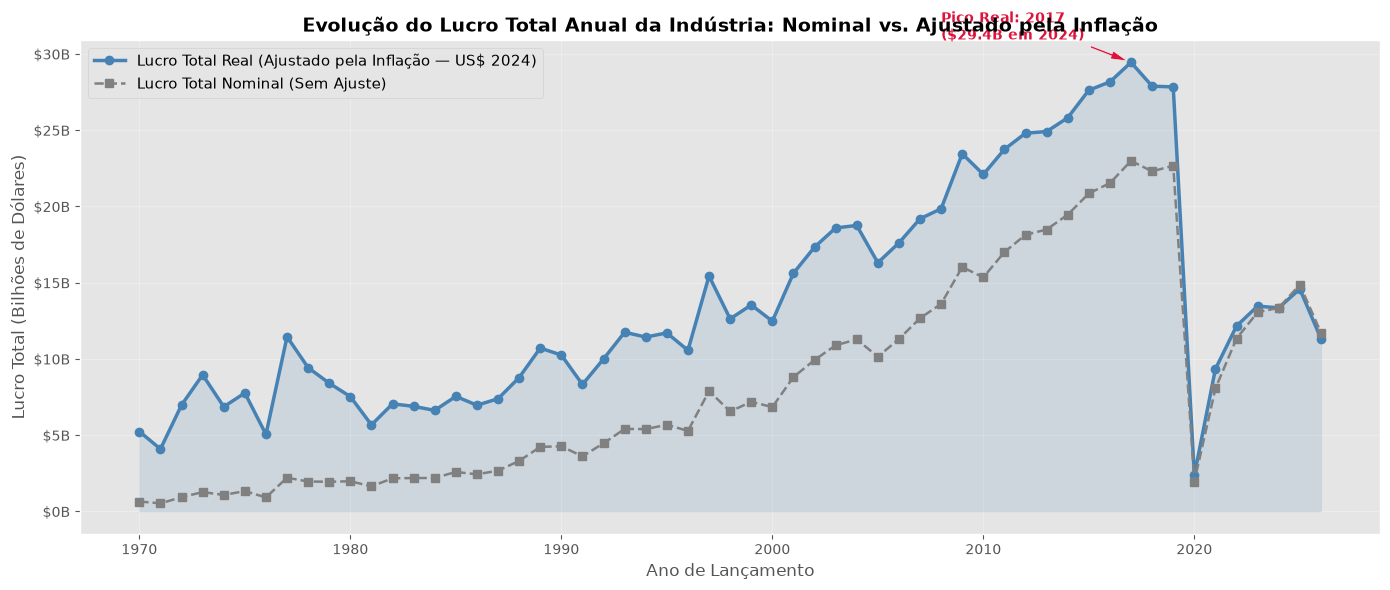

In [5]:
lucro_ano_moderno = lucro_por_ano[lucro_por_ano['year'] >= 1970]

plt.figure(figsize=(14, 6))

plt.plot(
    lucro_ano_moderno['year'],
    lucro_ano_moderno['lucro_total_adj_bi'],
    marker='o',
    color='steelblue',
    linewidth=2.5,
    label='Lucro Total Real (Ajustado pela Inflação — US$ 2024)'
)

plt.plot(
    lucro_ano_moderno['year'],
    lucro_ano_moderno['lucro_total_bi'],
    marker='s',
    color='gray',
    linestyle='--',
    linewidth=1.8,
    label='Lucro Total Nominal (Sem Ajuste)'
)

plt.fill_between(
    lucro_ano_moderno['year'],
    lucro_ano_moderno['lucro_total_adj_bi'],
    color='steelblue',
    alpha=0.15
)

# Pico Histórico Ajustado
ano_pico_adj = lucro_ano_moderno.loc[lucro_ano_moderno['lucro_total_adj_bi'].idxmax()]
plt.annotate(
    f"Pico Real: {int(ano_pico_adj['year'])}\n(${ano_pico_adj['lucro_total_adj_bi']:.1f}B em 2024)",
    xy=(ano_pico_adj['year'], ano_pico_adj['lucro_total_adj_bi']),
    xytext=(ano_pico_adj['year'] - 9, ano_pico_adj['lucro_total_adj_bi'] + 1.5),
    arrowprops=dict(facecolor='crimson', shrink=0.08, width=1.5, headwidth=6),
    fontweight='bold',
    color='crimson'
)

plt.title('Evolução do Lucro Total Anual da Indústria: Nominal vs. Ajustado pela Inflação', fontsize=14, fontweight='bold')
plt.xlabel('Ano de Lançamento', fontsize=12)
plt.ylabel('Lucro Total (Bilhões de Dólares)', fontsize=12)
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f'${value:.0f}B')
)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


### Gráfico 2: Lucro Médio vs. Lucro Mediano por Ano (Efeito Blockbuster)

A assimetria entre Média (puxada por blockbusters) e Mediana (filme típico).


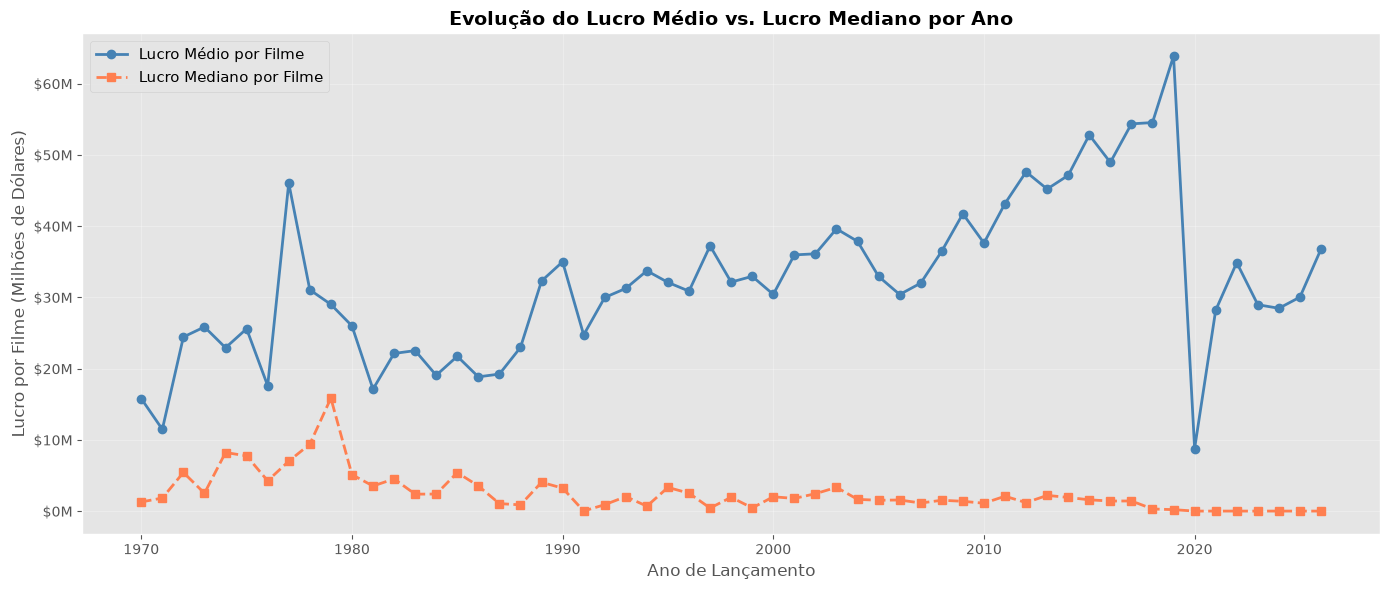

In [6]:
plt.figure(figsize=(14, 6))

plt.plot(
    lucro_ano_moderno['year'],
    lucro_ano_moderno['lucro_medio_mi'],
    marker='o',
    color='steelblue',
    linewidth=2,
    label='Lucro Médio por Filme'
)

plt.plot(
    lucro_ano_moderno['year'],
    lucro_ano_moderno['lucro_mediano_mi'],
    marker='s',
    color='coral',
    linewidth=2,
    linestyle='--',
    label='Lucro Mediano por Filme'
)

plt.title('Evolução do Lucro Médio vs. Lucro Mediano por Ano', fontsize=14, fontweight='bold')
plt.xlabel('Ano de Lançamento', fontsize=12)
plt.ylabel('Lucro por Filme (Milhões de Dólares)', fontsize=12)
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f'${value:.0f}M')
)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


### Gráfico 3: Lucro Total Acumulado por Década: Nominal vs. Ajustado pela Inflação

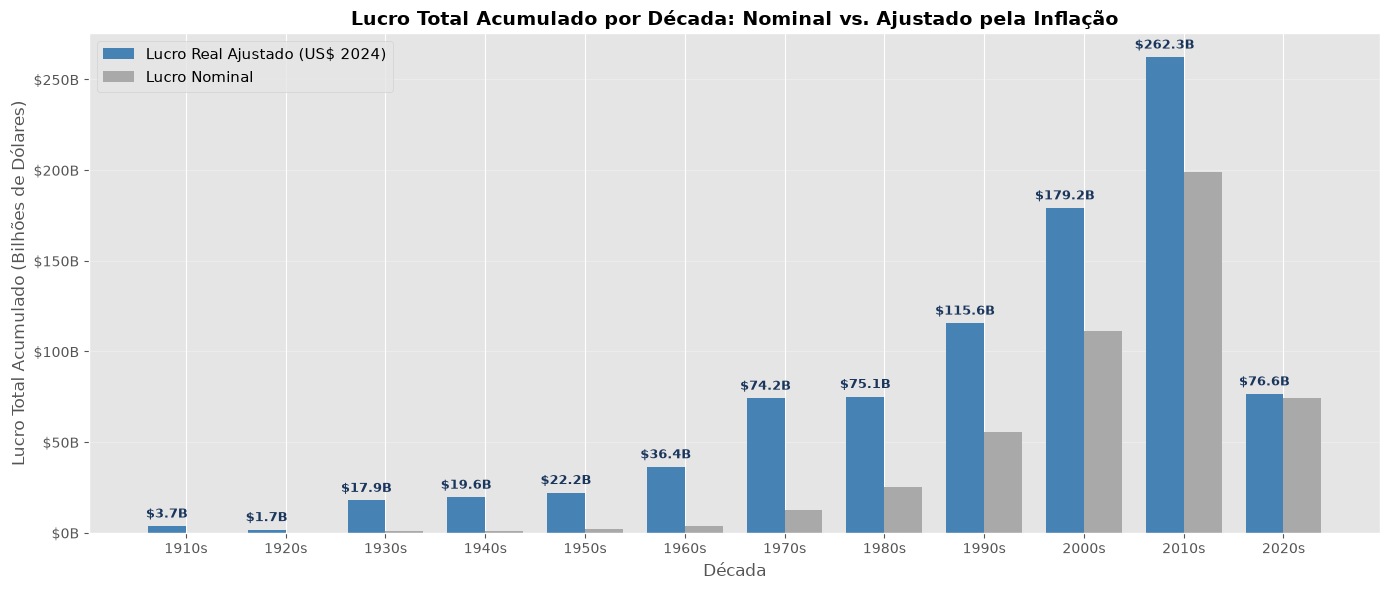

In [7]:
plt.figure(figsize=(14, 6))

x = np.arange(len(lucro_por_decada))
largura = 0.38

b1 = plt.bar(
    x - largura/2,
    lucro_por_decada['lucro_total_adj_bi'],
    largura,
    label='Lucro Real Ajustado (US$ 2024)',
    color='steelblue'
)

b2 = plt.bar(
    x + largura/2,
    lucro_por_decada['lucro_total_bi'],
    largura,
    label='Lucro Nominal',
    color='darkgray'
)

for barra in b1:
    altura = barra.get_height()
    if altura > 0:
        plt.annotate(
            f'${altura:.1f}B',
            xy=(barra.get_x() + barra.get_width() / 2, altura),
            xytext=(0, 4),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=9,
            fontweight='bold',
            color='#1a365d'
        )

plt.title('Lucro Total Acumulado por Década: Nominal vs. Ajustado pela Inflação', fontsize=14, fontweight='bold')
plt.xlabel('Década', fontsize=12)
plt.ylabel('Lucro Total Acumulado (Bilhões de Dólares)', fontsize=12)
plt.xticks(x, lucro_por_decada['decada_label'])
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f'${value:.0f}B')
)
plt.grid(axis='y', alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


## 2. Frequência e Volume de Produção dos Gêneros por Década

Nesta etapa descompactamos os gêneros (`explode('genres')`) e investigamos o **volume de filmes lançados** em cada gênero ao longo da história.  
Isso permite responder: quais gêneros são mais frequentes no cinema e como a preferência das produtoras evoluiu?


In [8]:
# Descompactar gêneros
df_genres = df.explode('genres').reset_index(drop=True)
df_genres['genre'] = df_genres['genres'].apply(
    lambda x: x.get('name') if isinstance(x, dict) else np.nan
)
df_genres = df_genres.dropna(subset=['genre', 'decada']).reset_index(drop=True)
df_genres['decada'] = df_genres['decada'].astype(int)
df_genres['decada_label'] = df_genres['decada'].astype(str) + 's'

print(f"Instâncias gênero-filme catalogadas: {len(df_genres):,}")


Instâncias gênero-filme catalogadas: 34,462


### Gráfico 4: Frequência Absoluta de Filmes por Gênero e Década (1970 – Presente)

Visualização em barras agrupadas comparando o volume de produções lançadas dos principais gêneros (Drama, Comédia, Thriller, Ação e Aventura) em cada década da era moderna.


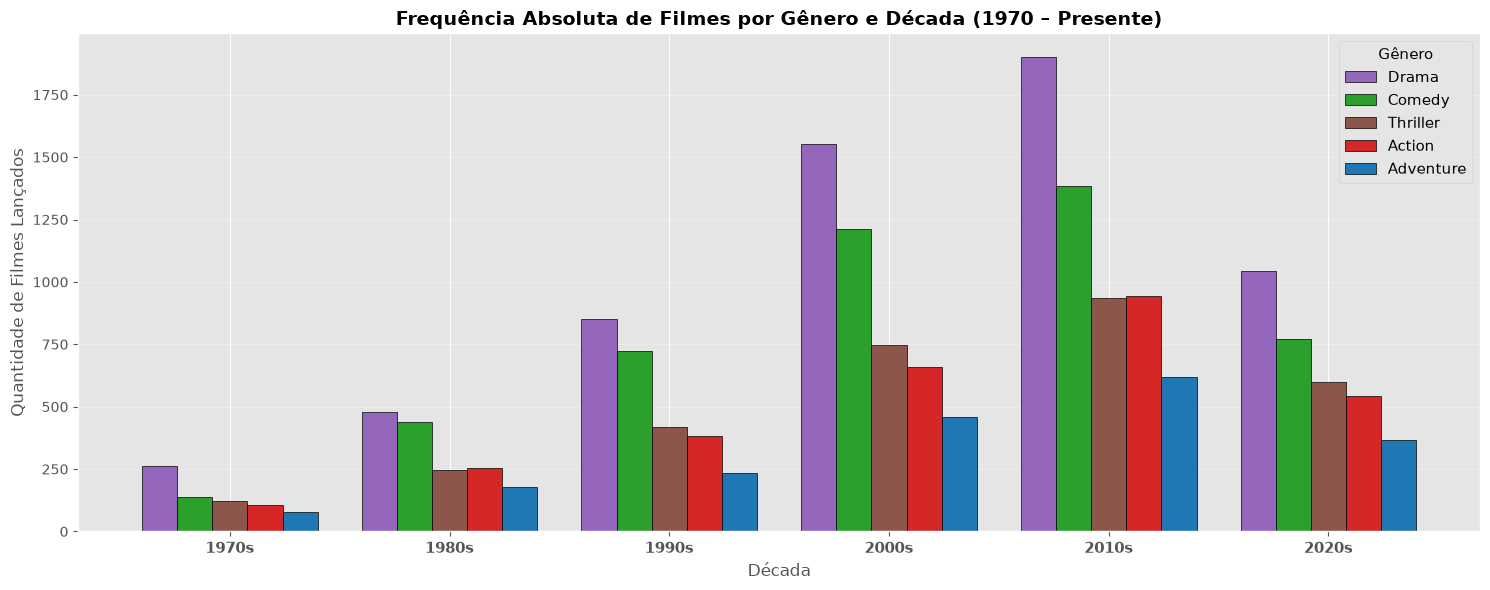

In [9]:
top_generos_freq = ['Drama', 'Comedy', 'Thriller', 'Action', 'Adventure']

frequencia_decada = (
    df_genres[df_genres['genre'].isin(top_generos_freq) & (df_genres['decada'] >= 1970)]
    .groupby(['decada', 'genre'])['id']
    .nunique()
    .unstack()[top_generos_freq]
)

plt.figure(figsize=(15, 6))

x = np.arange(len(frequencia_decada))
largura = 0.16
offsets = np.linspace(-2 * largura, 2 * largura, len(top_generos_freq))
cores = ['#9467bd', '#2ca02c', '#8c564b', '#d62728', '#1f77b4']

for i, genero in enumerate(top_generos_freq):
    plt.bar(
        x + offsets[i],
        frequencia_decada[genero],
        largura,
        label=genero,
        color=cores[i],
        edgecolor='black',
        linewidth=0.5
    )

plt.title('Frequência Absoluta de Filmes por Gênero e Década (1970 – Presente)', fontsize=14, fontweight='bold')
plt.xlabel('Década', fontsize=12)
plt.ylabel('Quantidade de Filmes Lançados', fontsize=12)
plt.xticks(x, [f"{int(d)}s" for d in frequencia_decada.index], fontsize=11, fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.legend(title='Gênero', fontsize=11, title_fontsize=11, frameon=True)
plt.tight_layout()
plt.show()


### Gráfico 5: Ranking Geral de Produções por Gênero no Dataset

Volume total de títulos catalogados por gênero em todo o histórico da base de dados, com a contagem exata anotada em cada barra.


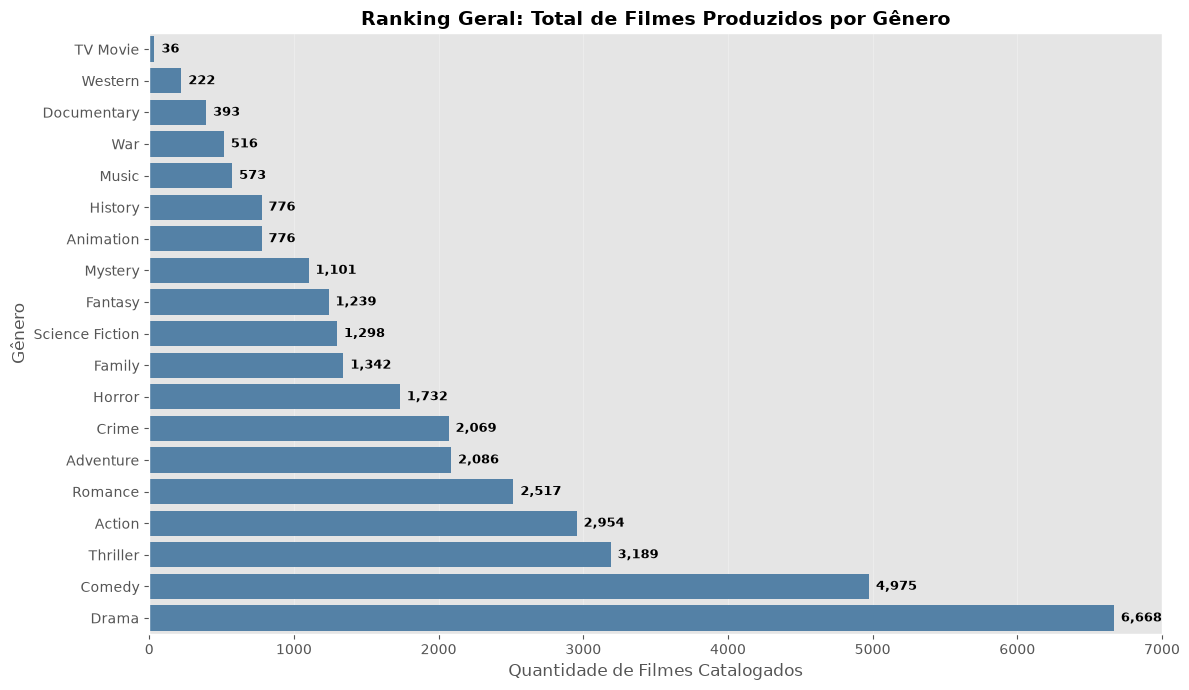

In [10]:
contagem_total_generos = df_genres['genre'].value_counts().sort_values(ascending=True)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    x=contagem_total_generos.values,
    y=contagem_total_generos.index,
    color='steelblue'
)

for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(
            f"{int(width):,}",
            xy=(width, p.get_y() + p.get_height() / 2),
            xytext=(5, 0),
            textcoords='offset points',
            ha='left',
            va='center',
            fontsize=9.5,
            fontweight='bold'
        )

ax.set_title('Ranking Geral: Total de Filmes Produzidos por Gênero', fontsize=14, fontweight='bold')
ax.set_xlabel('Quantidade de Filmes Catalogados', fontsize=12)
ax.set_ylabel('Gênero', fontsize=12)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


### Gráfico 6: O Grande Contraste: Volume de Produção (%) vs. Lucro Gerado (%)

Um dos insights mais ricos da ciência de dados cinematográfica: **os gêneros mais produzidos não são os mais lucrativos**.  
Na década de 2010s:
- **Drama** respondeu por quase **20% de todos os filmes produzidos**, mas gerou apenas **7,7% do lucro**.
- **Aventura**, com apenas **6,4% da produção**, gerou mais de **17% do lucro total**.
- **Ficção Científica**, com meros **3,6% da produção**, concentrou mais de **9% do lucro**.


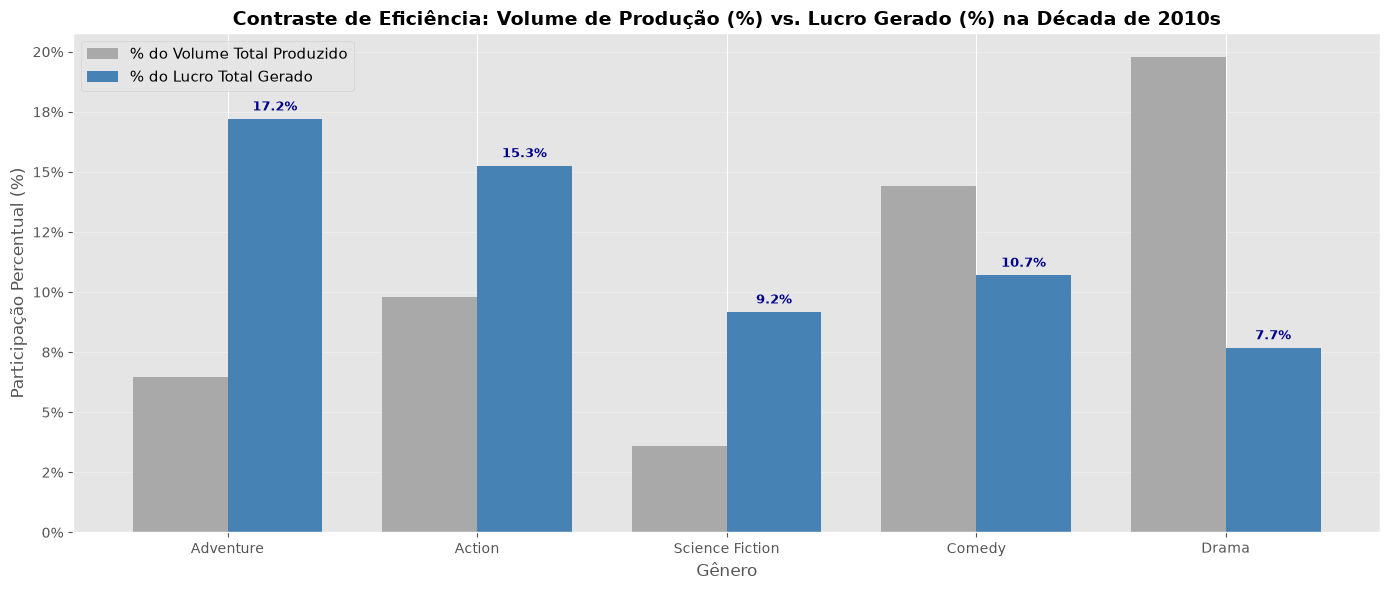

In [11]:
generos_contraste = ['Adventure', 'Action', 'Science Fiction', 'Comedy', 'Drama']

dados_contraste_2010 = df_genres[df_genres['decada'] == 2010].groupby('genre').agg(
    total_filmes=('id', 'count'),
    lucro_total=('profit_adj', 'sum')
).loc[generos_contraste]

pct_producao = (dados_contraste_2010['total_filmes'] / df_genres[df_genres['decada'] == 2010]['id'].count()) * 100
pct_lucro = (dados_contraste_2010['lucro_total'] / df_genres[df_genres['decada'] == 2010]['profit_adj'].sum()) * 100

plt.figure(figsize=(14, 6))

x = np.arange(len(generos_contraste))
largura = 0.38

b1 = plt.bar(
    x - largura/2,
    pct_producao,
    largura,
    label='% do Volume Total Produzido',
    color='darkgray'
)

b2 = plt.bar(
    x + largura/2,
    pct_lucro,
    largura,
    label='% do Lucro Total Gerado',
    color='steelblue'
)

for barra in b2:
    altura = barra.get_height()
    plt.annotate(
        f'{altura:.1f}%',
        xy=(barra.get_x() + barra.get_width() / 2, altura),
        xytext=(0, 4),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=9.5,
        fontweight='bold',
        color='darkblue'
    )

plt.title('Contraste de Eficiência: Volume de Produção (%) vs. Lucro Gerado (%) na Década de 2010s', fontsize=14, fontweight='bold')
plt.xlabel('Gênero', fontsize=12)
plt.ylabel('Participação Percentual (%)', fontsize=12)
plt.xticks(x, generos_contraste)
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f'{value:.0f}%')
)
plt.grid(axis='y', alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


## 3. Faturamento e Lucro dos Gêneros por Década (Ajustados pela Inflação)

Agora analisamos a lucratividade histórica real (em Dólares Constantes de 2024), observando a ascensão e queda dos gêneros líderes.


In [12]:
# Ranking Top 5 de Lucro Real por Década
top_5_generos_lucro_adj = (
    df_genres
    .groupby(['decada', 'genre'], as_index=False)['profit_adj']
    .sum()
    .sort_values(['decada', 'profit_adj'], ascending=[True, False])
    .assign(posicao=lambda x: x.groupby('decada').cumcount() + 1)
    .query('posicao <= 5')
    .pivot(index='decada', columns='posicao', values='genre')
    .rename(columns={
        1: 'Top 1 (Líder Real)',
        2: 'Top 2',
        3: 'Top 3',
        4: 'Top 4',
        5: 'Top 5'
    })
    .reset_index()
)

top_5_generos_lucro_adj['decada'] = top_5_generos_lucro_adj['decada'].astype(str) + 's'
top_5_generos_lucro_adj.rename(columns={'decada': 'Década'}, inplace=True)
top_5_generos_lucro_adj


posicao,Década,Top 1 (Líder Real),Top 2,Top 3,Top 4,Top 5
0,1910s,Drama,History,War,Adventure,Action
1,1920s,Drama,Romance,War,Music,Comedy
2,1930s,Drama,Romance,War,Fantasy,Family
3,1940s,Family,Animation,Drama,Fantasy,Romance
4,1950s,Drama,Romance,Fantasy,Family,Animation
5,1960s,Adventure,Drama,Family,Comedy,Thriller
6,1970s,Drama,Action,Thriller,Comedy,Adventure
7,1980s,Comedy,Action,Drama,Adventure,Science Fiction
8,1990s,Drama,Comedy,Action,Adventure,Thriller
9,2000s,Adventure,Comedy,Action,Drama,Fantasy


### Gráfico 7: Evolução Temporal do Lucro dos Principais Gêneros (Ajustado pela Inflação — US$ 2024)

Trajetória de lucro real de **Aventura, Ação, Comédia, Drama e Ficção Científica**.  
Com os dados ajustados pela inflação:
- **Drama** liderou até o final dos anos 1990;
- **Comédia** teve seu ápice real nos anos 1980 e 1990;
- **Aventura** e **Ação** disparam de forma astronômica a partir dos anos 2000, atingindo respectivamente **US$ 134,1 bilhões** e **US$ 118,9 bilhões** reais na década de 2010.


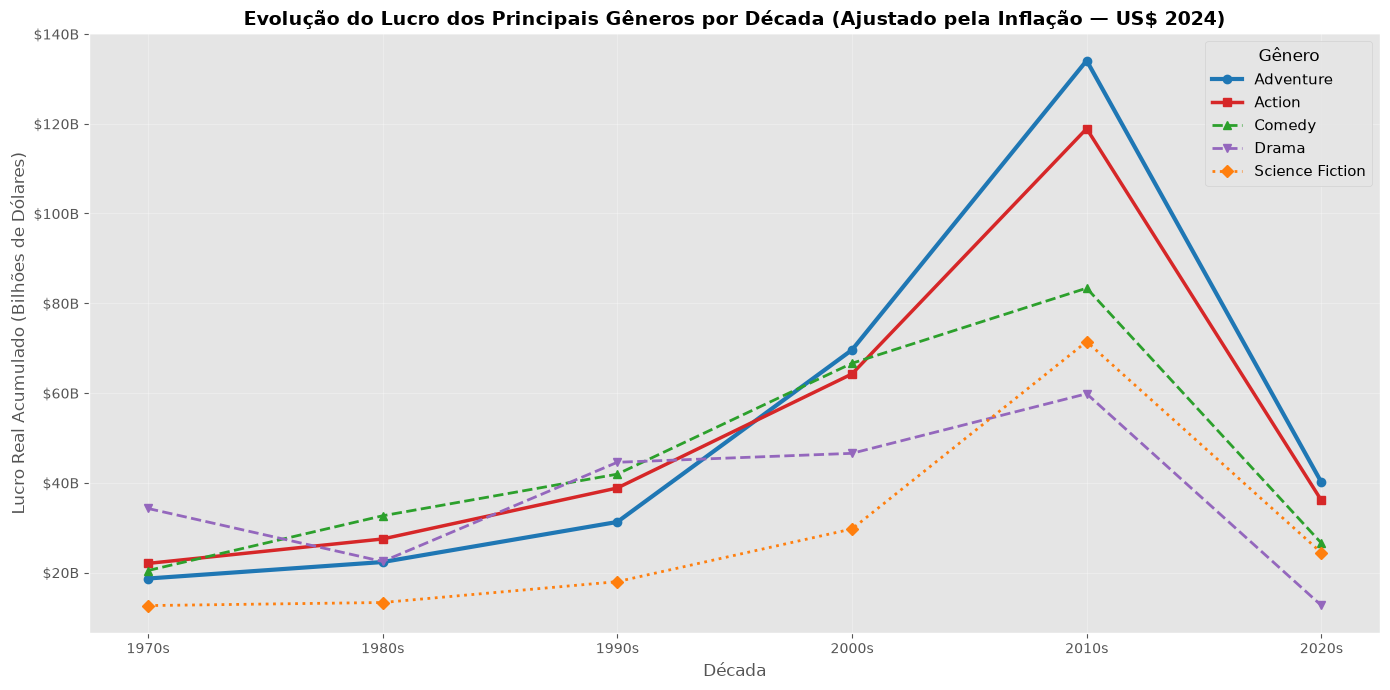

In [13]:
principais_generos = ['Adventure', 'Action', 'Comedy', 'Drama', 'Science Fiction']

lucro_top_adj = (
    df_genres[df_genres['genre'].isin(principais_generos) & (df_genres['decada'] >= 1970)]
    .groupby(['decada', 'genre'])['profit_adj']
    .sum()
    .unstack()
    / 1_000_000_000
)

plt.figure(figsize=(14, 7))

cores_generos = {
    'Adventure': '#1f77b4',
    'Action': '#d62728',
    'Comedy': '#2ca02c',
    'Drama': '#9467bd',
    'Science Fiction': '#ff7f0e'
}

estilos = {
    'Adventure': ('-', 'o', 3),
    'Action': ('-', 's', 2.5),
    'Comedy': ('--', '^', 2),
    'Drama': ('--', 'v', 2),
    'Science Fiction': (':', 'D', 2)
}

for genero in principais_generos:
    ls, m, lw = estilos[genero]
    plt.plot(
        lucro_top_adj.index,
        lucro_top_adj[genero],
        label=genero,
        color=cores_generos[genero],
        linestyle=ls,
        marker=m,
        linewidth=lw,
        markersize=6
    )

plt.title('Evolução do Lucro dos Principais Gêneros por Década (Ajustado pela Inflação — US$ 2024)', fontsize=14, fontweight='bold')
plt.xlabel('Década', fontsize=12)
plt.ylabel('Lucro Real Acumulado (Bilhões de Dólares)', fontsize=12)
plt.xticks(lucro_top_adj.index, [f"{int(d)}s" for d in lucro_top_adj.index])
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f'${value:.0f}B')
)
plt.grid(True, alpha=0.3)
plt.legend(title='Gênero', fontsize=11, title_fontsize=12)
plt.tight_layout()
plt.show()


### Gráfico 8: O Gênero Campeão em Cada Grande Era (Valores Reais em US$ 2024)

Subplots comparando os 5 maiores gêneros em cada era de 1980s a 2020s corrigidos pela inflação.


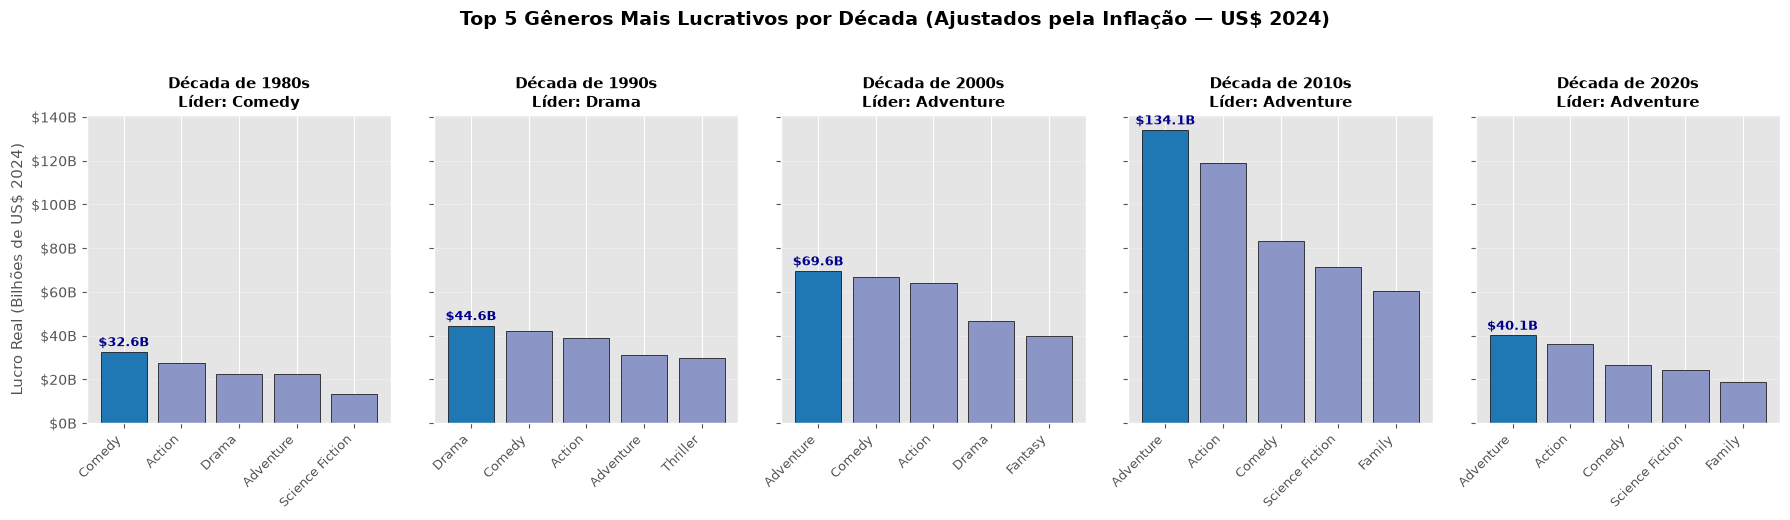

In [14]:
decadas_analise = [1980, 1990, 2000, 2010, 2020]
fig, axes = plt.subplots(1, 5, figsize=(18, 5), sharey=True)

for i, dec in enumerate(decadas_analise):
    ax = axes[i]
    dados_dec = (
        df_genres[df_genres['decada'] == dec]
        .groupby('genre')['profit_adj']
        .sum()
        .nlargest(5)
        / 1_000_000_000
    )
    
    cores = ['#1f77b4' if idx == 0 else '#8c96c6' for idx in range(len(dados_dec))]
    ax.bar(dados_dec.index, dados_dec.values, color=cores, edgecolor='black', linewidth=0.5)
    ax.set_title(f"Década de {dec}s\nLíder: {dados_dec.index[0]}", fontsize=11, fontweight='bold')
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9.5)
    ax.grid(axis='y', alpha=0.3)
    
    ax.annotate(
        f"${dados_dec.values[0]:.1f}B",
        xy=(0, dados_dec.values[0]),
        xytext=(0, 4),
        textcoords='offset points',
        ha='center',
        fontsize=9,
        fontweight='bold',
        color='darkblue'
    )

axes[0].set_ylabel('Lucro Real (Bilhões de US$ 2024)', fontsize=11)
axes[0].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f'${value:.0f}B')
)

plt.suptitle('Top 5 Gêneros Mais Lucrativos por Década (Ajustados pela Inflação — US$ 2024)', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


### Gráfico 9: Transformação do Market Share (%) de Lucro Real por Década

Gráfico de barras empilhadas normalizadas em 100% ilustrando a perda contínua de relevância de **Drama** (que cai de quase 30% nos anos 70 para 9% nos anos 2020) e a concentração em **Aventura**, **Ação** e **Sci-Fi** (> 70% juntas).


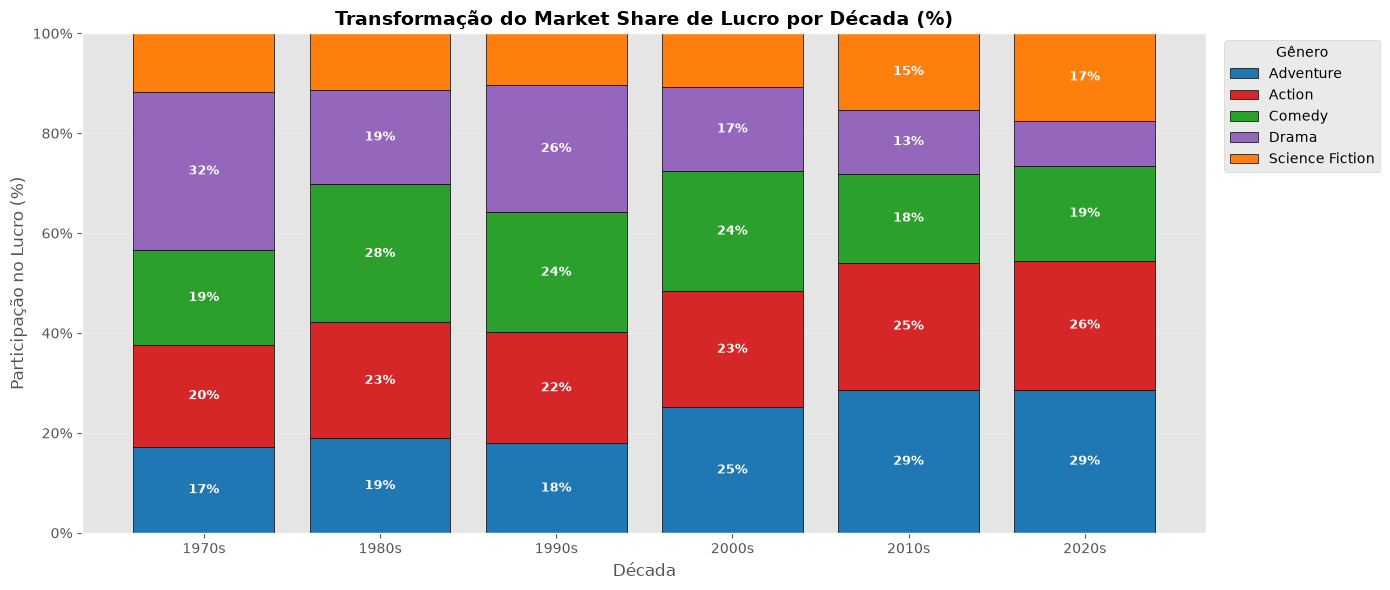

In [15]:
pivot_share_adj = (
    df_genres[df_genres['genre'].isin(principais_generos) & (df_genres['decada'] >= 1970)]
    .groupby(['decada', 'genre'])['profit_adj']
    .sum()
    .unstack()
)

pivot_share_pct = pivot_share_adj[principais_generos].div(pivot_share_adj[principais_generos].sum(axis=1), axis=0) * 100

plt.figure(figsize=(14, 6))

bottom = np.zeros(len(pivot_share_pct))
x_labels = [f"{int(d)}s" for d in pivot_share_pct.index]

for genero in principais_generos:
    valores = pivot_share_pct[genero].values
    plt.bar(
        x_labels,
        valores,
        bottom=bottom,
        label=genero,
        color=cores_generos[genero],
        edgecolor='black',
        linewidth=0.5
    )
    for idx, v in enumerate(valores):
        if v >= 12:
            plt.text(
                idx,
                bottom[idx] + v / 2,
                f"{v:.0f}%",
                ha='center',
                va='center',
                color='white',
                fontweight='bold',
                fontsize=9.5
            )
    bottom += valores

plt.title('Transformação do Market Share de Lucro por Década (%)', fontsize=14, fontweight='bold')
plt.xlabel('Década', fontsize=12)
plt.ylabel('Participação no Lucro (%)', fontsize=12)
plt.ylim(0, 100)
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f'{value:.0f}%')
)
plt.grid(axis='y', alpha=0.3)
plt.legend(title='Gênero', bbox_to_anchor=(1.01, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


### Gráfico 10: Lucro Mediano Real por Gênero na Era Contemporânea (2000 – Presente)

Lucro mediano corrigido pela inflação para avaliar a rentabilidade do filme típico em cada gênero.


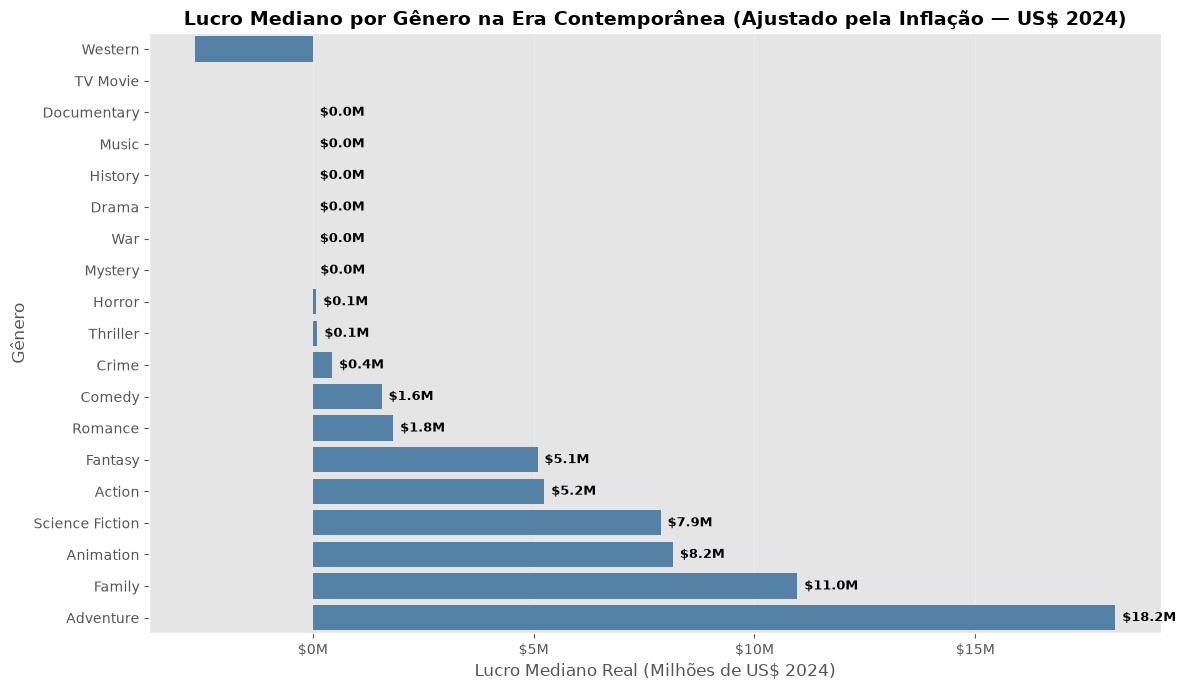

In [16]:
lucro_mediano_adj = (
    df_genres[df_genres['decada'] >= 2000]
    .groupby('genre')['profit_adj']
    .median()
    .div(1_000_000)
    .sort_values(ascending=True)
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    x=lucro_mediano_adj.values,
    y=lucro_mediano_adj.index,
    color='steelblue'
)

for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(
            f'${width:.1f}M',
            xy=(width, p.get_y() + p.get_height() / 2),
            xytext=(5, 0),
            textcoords='offset points',
            ha='left',
            va='center',
            fontsize=9.5,
            fontweight='bold'
        )

ax.set_title('Lucro Mediano por Gênero na Era Contemporânea (Ajustado pela Inflação — US$ 2024)', fontsize=14, fontweight='bold')
ax.set_xlabel('Lucro Mediano Real (Milhões de US$ 2024)', fontsize=12)
ax.set_ylabel('Gênero', fontsize=12)
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f'${value:.0f}M')
)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


### Tabela Histórica Especial: Maiores Sucessos de Bilheteria da História (Nominal vs. Ajustado)

Quando corrigido pela inflação, clássicos como ***...E o Vento Levou* (1939)** e ***Bambi* (1942)** assumem a liderança absoluta da rentabilidade histórica do cinema, superando em poder de compra os maiores sucessos da era Marvel.


In [17]:
top_10_historico = df.sort_values('profit_adj', ascending=False).head(10)

tabela_historica = pd.DataFrame({
    'Título': top_10_historico['title'],
    'Ano': top_10_historico['year'],
    'Lucro Real Ajustado ($B)': (top_10_historico['profit_adj'] / 1e9).round(2),
    'Lucro Nominal ($B)': (top_10_historico['profit'] / 1e9).round(2),
    'Multiplicador Inflação': top_10_historico['fator_inflacao'].round(1)
})

tabela_historica.reset_index(drop=True)


,Título,Ano,Lucro Real Ajustado ($B),Lucro Nominal ($B),Multiplicador Inflação
0,Gone with the Wind,1939,9.00,0.40,22.6
1,Bambi,1942,5.14,0.27,19.3
2,Snow White and the Seven Dwarfs,1938,4.09,0.18,22.3
3,Titanic,1997,4.04,2.06,2.0
4,Star Wars,1977,3.96,0.76,5.2
5,Avatar,2009,3.93,2.69,1.5
6,Pinocchio,1940,3.62,0.16,22.4
7,The Jungle Book,1967,3.52,0.37,9.4
8,Cinderella,1950,3.40,0.26,13.0
9,Avengers: Endgame,2019,3.17,2.58,1.2


# Insights e Conclusões

1. **O Impacto Revelador da Inflação:**
   - Em termos nominais, parece que o cinema quase não gerava lucro antes de 1970. Ao aplicar a correção monetária pelo **CPI-U (base 2024)**, descobre-se que clássicos como ***...E o Vento Levou* (1939)** geraram o equivalente a **US\$ 9,0 bilhões de lucro em valores de hoje**, superando o lucro real de qualquer filme moderno (incluindo *Avatar* e *Vingadores: Ultimato*).
   - O lucro real acumulado dos anos 1970 a 1990 é muito mais expressivo do que os valores nominais indicavam, revelando a solidez financeira das grandes comédias e dramas da época.

2. **Divergência entre Volume de Produção e Lucratividade:**
   - **Drama** e **Comédia** são, com ampla margem, os gêneros com maior quantidade absoluta de filmes produzidos em todas as décadas analisadas.
   - Contudo, na era contemporânea, **Aventura** e **Ficção Científica** geram quase o triplo de lucro proporcional ao seu volume de lançamentos. Aventura produziu apenas 6,4% dos filmes dos anos 2010s, mas concentrou mais de 17% de todo o lucro gerado.

3. **A Migração de Perfil da Indústria (Drama vs. Ação/Aventura):**
   - O gênero **Drama** encolheu de quase **30% do market share de lucro nos anos 1970 para apenas 9% nos anos 2020**.
   - Em contrapartida, **Aventura, Ação e Ficção Científica** cresceram de forma sustentada e hoje dominam mais de **71%** do lucro dos gêneros líderes, refletindo o modelo global focado em espetáculos visuais, CGI e universos cinematográficos.

4. **Os Gêneros Mais Seguros para o Filme Típico:**
   - A análise de **lucro mediano** (imune a outliers) demonstra que **Aventura (US\$ 16,8M)**, **Família (US\$ 10,7M)**, **Animação (US\$ 7,5M)** e **Ficção Científica (US\$ 7,4M)** em valores reais de 2024 são os investimentos mais previsíveis e com menor taxa de fracasso para os estúdios.
